# Predicting Tox21 assay activity from molecular structure
Logistic regression, random forest and gradient boosting on Morgan fingerprints, evaluated on scaffold splits. On NR-AR the random forest reached a test AUROC of 0.728 (57 active test molecules), and it beat random guessing on all 12 assays. The README has the background and limitations.

In [2]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from tdc.single_pred import Tox

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

### Load the data
NR-AR assay from Tox21 via TDC. 

In [4]:
data = Tox(name="Tox21", label_name="NR-AR")
df = data.get_data()
print(df.shape)
print(df["Y"].value_counts())
df.head()

Found local copy...
Loading...
Done!


(7265, 3)
Y
0.0    6956
1.0     309
Name: count, dtype: int64


,Drug_ID,Drug,Y
0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,0.0
1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,0.0
2,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,0.0
3,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,0.0
4,TOX5110,CC(C)(C)OOC(C)(C)CCC(C)(C)OOC(C)(C)C,0.0


7,265 molecules, 309 active (4.3%), so the classes are heavily imbalanced.

### Turn molecules into fingerprints
Convert each SMILES string into a 2048-bit Morgan fingerprint with RDKit.

In [7]:
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def smiles_to_fp(smiles):
    # SMILES text -> molecule -> list of 2,048 zeros and ones
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return gen.GetFingerprintAsNumPy(mol)

def featurise(frame):
    # Turn a table of SMILES and labels into X (fingerprints) and y (labels)
    fps = frame["Drug"].apply(smiles_to_fp)
    mask = fps.notnull()
    X = np.stack(fps[mask].values)
    y = frame.loc[mask, "Y"].values
    return X, y

### Scaffold Split
Split by scaffold into train, validation and test.

In [9]:
split = data.get_split(method="scaffold", seed=1)
train_df = split["train"]
valid_df = split["valid"]
test_df = split["test"]
print(len(train_df), len(valid_df), len(test_df))

100%|████████████████████████████████████| 7265/7265 [00:01<00:00, 6770.62it/s]

5085 726 1454


### Storing in SQL
Store splits in SQLite and check the class balance with GROUP BY.

In [11]:
train_df["split"] = "train"
valid_df["split"] = "valid"
test_df["split"] = "test"

all_df = pd.concat([train_df, valid_df, test_df])

conn = sqlite3.connect("tox21.db")
all_df.to_sql("nr_ar_results", conn, if_exists="replace", index=False)

query = """
SELECT split, COUNT(*) AS n_molecules, SUM(Y) AS n_active, ROUND(AVG(Y), 3) AS fraction_active
FROM nr_ar_results
GROUP BY split
"""
pd.read_sql(query, conn)

,split,n_molecules,n_active,fraction_active
0,test,1454,57.0,0.039
1,train,5085,168.0,0.033
2,valid,726,84.0,0.116


Validation has a much higher share of actives (11.6%) than train or test.

### Read the splits back and fingerprint them
Read each split back out of the database with SQL, then turn it into fingerprints. The row counts should match the split sizes (5,085, 726 and 1,454).

In [14]:
def load_split(name):
    q = "SELECT Drug, Y FROM nr_ar_results WHERE split = ?"
    return pd.read_sql(q, conn, params=(name,))

train_df = load_split("train")
valid_df = load_split("valid")
test_df = load_split("test")

X_train, y_train = featurise(train_df)
X_valid, y_valid = featurise(valid_df)
X_test, y_test = featurise(test_df)
print(X_train.shape, X_valid.shape, X_test.shape)

(5085, 2048) (726, 2048) (1454, 2048)


### Train models
Train 3 models: logistic regression, random forest and gradient boosting. Score them on the validation set using AUROC and average precision (AP).

In [16]:
model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train, y_train)
probs = model.predict_proba(X_valid)[:, 1]

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)
rf_probs = rf.predict_proba(X_valid)[:, 1]

gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=4,
                                    class_weight="balanced", random_state=1)
gb.fit(X_train, y_train)
gb_probs = gb.predict_proba(X_valid)[:, 1]

for name, p in [("Logistic regression", probs), ("Random forest", rf_probs), ("Gradient boosting", gb_probs)]:
    print(name, "AUROC:", round(roc_auc_score(y_valid, p), 3),
          "AP:", round(average_precision_score(y_valid, p), 3))
print("Random guessing (AP):", round(y_valid.mean(), 3))

Logistic regression AUROC: 0.896 AP: 0.724
Random forest AUROC: 0.912 AP: 0.834
Gradient boosting AUROC: 0.903 AP: 0.812
Random guessing (AP): 0.116


With only 84 validation actives, I cannot be sure which is best.

### Plot Precision-recall curve

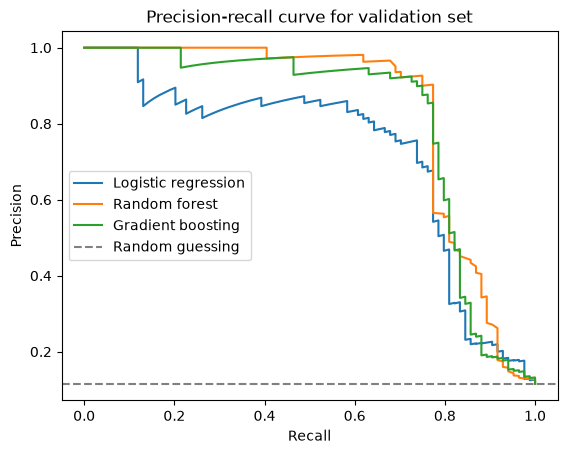

In [19]:
fig, ax = plt.subplots()
for name, scores in [("Logistic regression", probs), ("Random forest", rf_probs), ("Gradient boosting", gb_probs)]:
    precision, recall, _ = precision_recall_curve(y_valid, scores)
    ax.plot(recall,precision, label=name)
ax.axhline(y_valid.mean(), linestyle="--", color="grey", label="Random guessing")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curve for validation set")
ax.legend()
plt.savefig("precision_recall.png", dpi=150, bbox_inches="tight")
plt.show()

### Tune gradient boosting
Grid search over depth and learning rate, scored on validation only.

In [21]:
results = []
for depth in [2, 4, 6]:
    for lr in [0.02, 0.05, 0.1]:
        candidate = HistGradientBoostingClassifier(max_iter=300, learning_rate=lr, max_depth=depth,
                                                   class_weight="balanced", random_state=1)
        candidate.fit(X_train, y_train)
        p = candidate.predict_proba(X_valid)[:, 1]
        results.append({"max_depth": depth, "learning_rate": lr,
                        "auroc": roc_auc_score(y_valid, p),
                        "avg_precision": average_precision_score(y_valid, p)})

pd.DataFrame(results).sort_values("avg_precision", ascending=False).reset_index(drop=True)

,max_depth,learning_rate,auroc,avg_precision
0,4,0.02,0.908267,0.828011
1,6,0.02,0.910788,0.818758
2,4,0.05,0.902667,0.811749
3,2,0.02,0.902620,0.806806
4,2,0.05,0.911335,0.804991
5,2,0.10,0.904808,0.790799
6,4,0.10,0.892876,0.790136
7,6,0.10,0.895082,0.783683
8,6,0.05,0.901294,0.780010


Average precision ranged from 0.78 to 0.83, about level with the untuned model.

### Final Evaluation
Random forest chosen from validation scores before the test set was used. Run once on the test set, with no changes afterwards.

In [24]:
rf_test_probs = rf.predict_proba(X_test)[:, 1]

print("AUROC:", roc_auc_score(y_test, rf_test_probs))
print("Average precision:", average_precision_score(y_test, rf_test_probs))
print("Random guessing (AP):", y_test.mean())
print("Actives in test set:", int(y_test.sum()))

AUROC: 0.7277750568260307
Average precision: 0.23232171895288084
Random guessing (AP): 0.039202200825309494
Actives in test set: 57


### Bootstrap Interval
95% intervals from 1,000 resamples of the test set.

In [26]:
rng = np.random.default_rng(1)
n = len(y_test)
boot_auroc, boot_ap = [], []

for _ in range(1000):
    idx = rng.integers(0, n, size=n)
    if y_test[idx].sum() == 0:
        continue
    boot_auroc.append(roc_auc_score(y_test[idx], rf_test_probs[idx]))
    boot_ap.append(average_precision_score(y_test[idx], rf_test_probs[idx]))

print("AUROC 95% interval:", np.percentile(boot_auroc, [2.5, 97.5]))
print("AP 95% interval:", np.percentile(boot_ap, [2.5, 97.5]))

AUROC 95% interval: [0.65636312 0.80295446]
AP 95% interval: [0.1385038  0.36930216]


### Feature Importance
The 15 fingerprint bits the random forest relies on most, with how many training molecules have each and what fraction of those are active (base rate 3.3%).

In [28]:
importances = rf.feature_importances_
top = np.argsort(importances)[::-1][:15]

print("bit, importance, molecules with bit, fraction active")
for bit in top:
    has_bit = X_train[:, bit] == 1
    print(bit, round(importances[bit], 4), has_bit.sum(), round(y_train[has_bit].mean(), 3))
print("Base rate of actives in training:", round(y_train.mean(), 3))

bit, importance, molecules with bit, fraction active
519 0.0132 128 0.539
1060 0.0118 446 0.175
622 0.0112 98 0.571
529 0.011 74 0.676
84 0.0105 106 0.509
1162 0.0101 213 0.3
1738 0.0101 223 0.278
1274 0.0101 399 0.185
314 0.0096 591 0.125
1019 0.0095 772 0.113
242 0.0087 85 0.541
1325 0.0081 430 0.167
926 0.0079 951 0.095
408 0.0076 60 0.733
807 0.0075 3228 0.043
Base rate of actives in training: 0.033


## Store the 12 assays in SQL
Load all 12 assays into two tables, `molecules` and `labels`, linked by `Drug_ID`. A JOIN reads one assay back out.

In [30]:
assays = ["NR-AR", "NR-AR-LBD", "NR-AhR", "NR-Aromatase", "NR-ER", "NR-ER-LBD",
          "NR-PPAR-gamma", "SR-ARE", "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53"]

frames = []
for assay in assays:
    d = Tox(name="Tox21", label_name=assay).get_data()
    d["assay"] = assay
    frames.append(d)
labels_df = pd.concat(frames)

molecules = labels_df[["Drug_ID", "Drug"]].drop_duplicates()
labels = labels_df[["Drug_ID", "assay", "Y"]]
molecules.to_sql("molecules", conn, if_exists="replace", index=False)
labels.to_sql("labels", conn, if_exists="replace", index=False)
print(len(molecules), len(labels))

def load_assay(assay):
    q = """
    SELECT m.Drug, l.Y
    FROM molecules AS m
    JOIN labels AS l ON m.Drug_ID = l.Drug_ID
    WHERE l.assay = ?
    """
    return pd.read_sql(q, conn, params=(assay,))

ar = load_assay("NR-AR")
print(ar.shape, ar["Y"].sum())

Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!


7831 77946
(7265, 2) 309.0


The JOIN on NR-AR returns 7,265 molecules and 309 actives, matching the original data.

### Random forest on all 12 assays
Same forest and settings as NR-AR, with no per-assay tuning and a separate scaffold split for each assay. Results are saved to SQL and queried. 

In [33]:
rows = []
for assay in assays:
    d = Tox(name="Tox21", label_name=assay)
    sp = d.get_split(method="scaffold", seed=1)
    Xtr, ytr = featurise(sp["train"])
    Xte, yte = featurise(sp["test"])

    m = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=1, n_jobs=-1)
    m.fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]

    rows.append({"assay": assay, "n_test": len(yte), "n_active_test": int(yte.sum()),
                 "auroc": roc_auc_score(yte, p),
                 "avg_precision": average_precision_score(yte, p),
                 "floor": yte.mean()})

results_12 = pd.DataFrame(rows)
results_12.rename(columns={"floor": "random_floor"}).to_sql("assay_results", conn, if_exists="replace", index=False)

query = """
SELECT assay,
       n_test,
       n_active_test,
       ROUND(auroc, 3) AS auroc,
       ROUND(avg_precision, 3) AS avg_precision,
       ROUND(random_floor, 3) AS random_floor,
       ROUND(avg_precision / random_floor, 1) AS lift
FROM assay_results
ORDER BY lift DESC
"""
pd.read_sql(query, conn)

Found local copy...
Loading...
Done!
100%|████████████████████████████████████| 7265/7265 [00:01<00:00, 6706.25it/s]
Found local copy...
Loading...
Done!
100%|████████████████████████████████████| 6758/6758 [00:00<00:00, 7048.18it/s]
Found local copy...
Loading...
Done!
100%|████████████████████████████████████| 6549/6549 [00:01<00:00, 5677.41it/s]
Found local copy...
Loading...
Done!
100%|████████████████████████████████████| 5821/5821 [00:00<00:00, 7342.55it/s]
Found local copy...
Loading...
Done!
100%|████████████████████████████████████| 6193/6193 [00:00<00:00, 7306.43it/s]
Found local copy...
Loading...
Done!
100%|████████████████████████████████████| 6955/6955 [00:00<00:00, 7070.28it/s]
Found local copy...
Loading...
Done!
100%|████████████████████████████████████| 6450/6450 [00:00<00:00, 7307.84it/s]
Found local copy...
Loading...
Done!
100%|████████████████████████████████████| 5832/5832 [00:00<00:00, 8168.33it/s]
Found local copy...
Loading...
Done!
100%|██████████████████████

,assay,n_test,n_active_test,auroc,avg_precision,random_floor,lift
0,NR-AR-LBD,1353,106,0.906,0.750,0.078,9.6
1,NR-AR,1454,57,0.728,0.232,0.039,5.9
2,NR-PPAR-gamma,1290,32,0.786,0.145,0.025,5.9
3,NR-ER-LBD,1392,111,0.762,0.458,0.080,5.7
4,NR-AhR,1311,176,0.864,0.552,0.134,4.1
5,SR-HSE,1295,92,0.742,0.275,0.071,3.9
6,SR-ATAD5,1415,68,0.723,0.170,0.048,3.5
7,SR-p53,1356,136,0.729,0.332,0.100,3.3
8,NR-ER,1239,216,0.739,0.507,0.174,2.9
9,SR-MMP,1163,259,0.787,0.579,0.223,2.6


`lift` is average precision divided by the random-guessing floor for that assay.